# E.2 Pool two HWE populations

Two populations each meet Hardy–Weinberg equilibrium (HWE). Can their combined genotype sample fail an HWE comparison?

At allele frequency $p$, the HWE genotype probabilities are $p^2$, $2p(1-p)$, and $(1-p)^2$. Take equal-sized populations at $p_1=0.8$ and $p_2=0.2$. Within each population, heterozygosity is $0.32$. At the pooled allele frequency $\bar p=0.5$, HWE predicts $0.50$. Pooling preserves the actual heterozygote counts, so the combined sample has a deficit.


## The same difference has two summaries

Let $H_S$ be mean within-population heterozygosity and $H_T=2\bar p(1-\bar p)$ the HWE value at the pooled frequency. Then $F_{ST}=(H_T-H_S)/H_T$. We expect $H_S=0.32$, $H_T=0.50$, and $F_{ST}=0.36$. The heterozygote deficit is the Wahlund effect. No individual must be inbred for it to occur.


In [1]:
library(hpgR)

p <- c(population_1 = 0.8, population_2 = 0.2)
pool <- poolAlleleFrequencies(p)
genotype <- pool$genotype
pooled <- pool$pooled
pooled_p <- pool$pooled_p
H_S <- pool$H_S
H_T <- pool$H_T
F_ST <- pool$F_ST
stopifnot(all(abs(colSums(genotype) - 1) < 1e-12))
stopifnot(abs(H_S - 0.32) < 1e-12, abs(H_T - 0.5) < 1e-12)
stopifnot(abs(F_ST - 0.36) < 1e-12)
c(within = H_S, pooled_HWE = H_T, F_ST = F_ST)

within pooled_HWE       F_ST 
      0.32       0.50       0.36

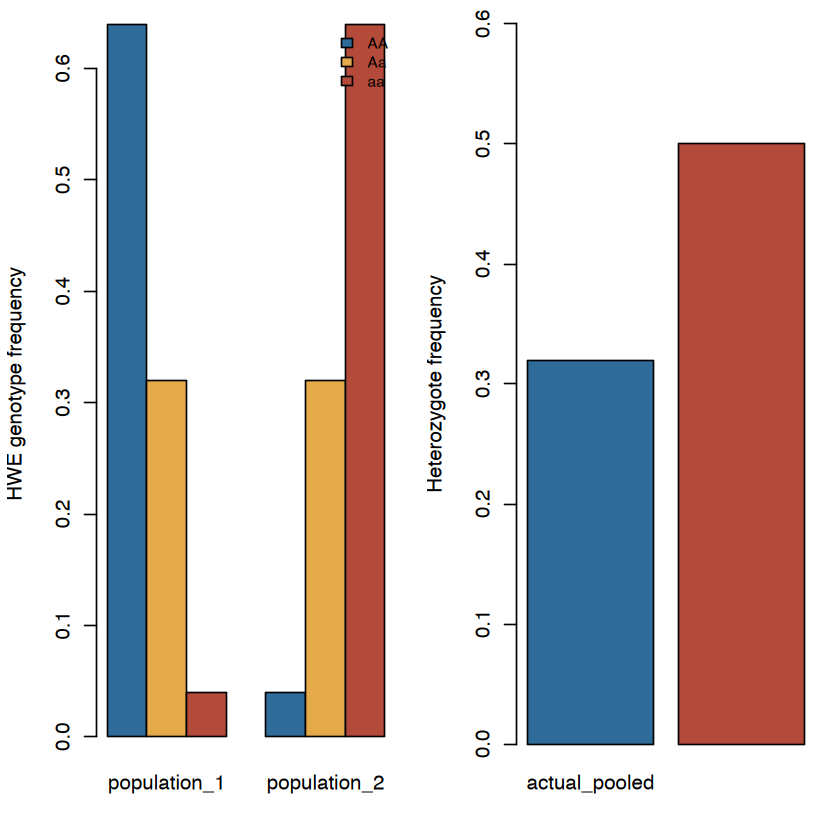

In [2]:
old_par <- par(mfrow = c(1, 2), mar = c(4, 4, 1, 1))
barplot(genotype, beside = TRUE, col = c('#306C9A', '#E5AA49', '#B44A3A'),
        names.arg = names(p), ylab = 'HWE genotype frequency')
legend('topright', legend = rownames(genotype),
       fill = c('#306C9A', '#E5AA49', '#B44A3A'), bty = 'n', cex = 0.75)
barplot(c(actual_pooled = H_S, HWE_at_pooled_p = H_T),
        col = c('#306C9A', '#B44A3A'), ylim = c(0, 0.6),
        ylab = 'Heterozygote frequency')
par(old_par)

The first plot shows that each population has its own HWE genotype distribution. The second compares the heterozygotes actually pooled with the number predicted if all copies formed one randomly mating population. The difference is caused by the grouping of samples.

## What to remember

The Wahlund effect and $F_{ST}$ read the same allele-frequency variation in different ways. An HWE deficit alone cannot identify inbreeding; first ask whether distinct populations were pooled.

**Sources.** Pritchard, *An Owner's Guide to the Human Genome*, Section 2.4; Gorroochurn, *Population Genetics Notes*, Sections 9.5–9.7. The $0.8/0.2$ values reproduce the lecture's two-population calculation; genotype probabilities are exact model values, not observed data.
